# 05 — Solar PV Context and Heat-Pump Adoption

This notebook preserves the exploratory solar-adoption analysis used to test whether prior household clean-energy adoption may be associated with municipal heat-pump adoption.

The original MassCEC PTS cleaning, municipality aggregation, per-household normalization, heat-pump merging, correlations, plots, and regression code are retained.


## Source provenance

This polished notebook consolidates the following original work:

- `solaradoption(1).ipynb` — MassCEC Production Tracking System solar-data cleaning and municipality-level solar-vs-heat-pump adoption analysis.

No analytical code from the source files was silently replaced. The purpose of this version is to make the workflow easier to follow in a public research repository.


---
## Original analysis section: `solaradoption(1).ipynb`

**What this section contains:** MassCEC Production Tracking System solar-data cleaning and municipality-level solar-vs-heat-pump adoption analysis.

> The code and outputs below are preserved from the original notebook/work file. They have not been rewritten or re-derived for this polished repository version.


In [1]:
from google.colab import files
uploaded = files.upload()

Saving Solar-PV-Systems-in-MA-as-of-Jan-2025.xlsx to Solar-PV-Systems-in-MA-as-of-Jan-2025.xlsx


In [2]:
import os
os.listdir()

['.config', 'Solar-PV-Systems-in-MA-as-of-Jan-2025.xlsx', 'sample_data']

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_name = "Solar-PV-Systems-in-MA-as-of-Jan-2025.xlsx"

solar_raw = pd.read_excel(file_name, skiprows=7)
solar_raw.head()

,"5. A subset 1286 SMART projects are currently missing Facility type and are listed as 'Other' in this report, highlighted orange.",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16
0,"6. If you notice data errors, please contact p...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,"Capacity \n(DC, kW)",Date In Service,Total Cost with Design Fees,Total Grant,City,Zip,County,Program Name,Facility Type,Installer,Module Manufacturer,Inverter Manufacturer,Meter Manufacturer,Utility,3rd Party Owner,SREC Eligible,Estimated Annual Production (kWhr)
3,12.75,2024-12-06 00:00:00,37740,0,Sharon,2067,NaN,NaN,Residential (3 or fewer dwelling units per bui...,SmartRoof Capital,Hanwha SolarOne,Enphase Energy,Enphase Energy,NSTAR (DBA EverSource),N,N,12466
4,10.2,2024-11-07 00:00:00,33864,0,Falmouth,2574,NaN,NaN,Residential (3 or fewer dwelling units per bui...,SmartRoof Capital,Hanwha SolarOne,Enphase Energy,Enphase Energy,NSTAR (DBA EverSource),N,N,11836


In [4]:
solar_raw = pd.read_excel(file_name, skiprows=9)

solar_raw.head()

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16
0,"Capacity \n(DC, kW)",Date In Service,Total Cost with Design Fees,Total Grant,City,Zip,County,Program Name,Facility Type,Installer,Module Manufacturer,Inverter Manufacturer,Meter Manufacturer,Utility,3rd Party Owner,SREC Eligible,Estimated Annual Production (kWhr)
1,12.75,2024-12-06 00:00:00,37740,0,Sharon,2067,NaN,NaN,Residential (3 or fewer dwelling units per bui...,SmartRoof Capital,Hanwha SolarOne,Enphase Energy,Enphase Energy,NSTAR (DBA EverSource),N,N,12466
2,10.2,2024-11-07 00:00:00,33864,0,Falmouth,2574,NaN,NaN,Residential (3 or fewer dwelling units per bui...,SmartRoof Capital,Hanwha SolarOne,Enphase Energy,Enphase Energy,NSTAR (DBA EverSource),N,N,11836
3,8.28,2024-10-25 00:00:00,42928,0,Provincetown,2657,Barnstable,Solar Massachusetts Renewable Target (SMART),Residential (3 or fewer dwelling units per bui...,SolarCity DBA Tesla Energy,Tesla Inc.,Tesla,SMART Meter,NSTAR (DBA EverSource),N,N,8884
4,16.575,2024-10-18 00:00:00,31700,0,Weymouth,2190,NaN,NaN,Residential (3 or fewer dwelling units per bui...,SmartRoof Capital,Hanwha SolarOne,Enphase Energy,Enphase Energy,National Grid,N,N,9564


In [5]:
solar_raw.columns = (
    solar_raw.columns
    .astype(str)
    .str.strip()
    .str.replace("\n", " ", regex=False)
)

solar_raw.columns.tolist()

['Unnamed: 0',
 'Unnamed: 1',
 'Unnamed: 2',
 'Unnamed: 3',
 'Unnamed: 4',
 'Unnamed: 5',
 'Unnamed: 6',
 'Unnamed: 7',
 'Unnamed: 8',
 'Unnamed: 9',
 'Unnamed: 10',
 'Unnamed: 11',
 'Unnamed: 12',
 'Unnamed: 13',
 'Unnamed: 14',
 'Unnamed: 15',
 'Unnamed: 16']

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_name = "Solar-PV-Systems-in-MA-as-of-Jan-2025.xlsx"

solar_raw = pd.read_excel(file_name, skiprows=9)

solar_raw.columns = (
    solar_raw.columns
    .astype(str)
    .str.strip()
    .str.replace("\n", " ", regex=False)
)

solar_raw.head()

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16
0,"Capacity \n(DC, kW)",Date In Service,Total Cost with Design Fees,Total Grant,City,Zip,County,Program Name,Facility Type,Installer,Module Manufacturer,Inverter Manufacturer,Meter Manufacturer,Utility,3rd Party Owner,SREC Eligible,Estimated Annual Production (kWhr)
1,12.75,2024-12-06 00:00:00,37740,0,Sharon,2067,NaN,NaN,Residential (3 or fewer dwelling units per bui...,SmartRoof Capital,Hanwha SolarOne,Enphase Energy,Enphase Energy,NSTAR (DBA EverSource),N,N,12466
2,10.2,2024-11-07 00:00:00,33864,0,Falmouth,2574,NaN,NaN,Residential (3 or fewer dwelling units per bui...,SmartRoof Capital,Hanwha SolarOne,Enphase Energy,Enphase Energy,NSTAR (DBA EverSource),N,N,11836
3,8.28,2024-10-25 00:00:00,42928,0,Provincetown,2657,Barnstable,Solar Massachusetts Renewable Target (SMART),Residential (3 or fewer dwelling units per bui...,SolarCity DBA Tesla Energy,Tesla Inc.,Tesla,SMART Meter,NSTAR (DBA EverSource),N,N,8884
4,16.575,2024-10-18 00:00:00,31700,0,Weymouth,2190,NaN,NaN,Residential (3 or fewer dwelling units per bui...,SmartRoof Capital,Hanwha SolarOne,Enphase Energy,Enphase Energy,National Grid,N,N,9564


In [8]:
solar_raw.columns.tolist()

['Unnamed: 0',
 'Unnamed: 1',
 'Unnamed: 2',
 'Unnamed: 3',
 'Unnamed: 4',
 'Unnamed: 5',
 'Unnamed: 6',
 'Unnamed: 7',
 'Unnamed: 8',
 'Unnamed: 9',
 'Unnamed: 10',
 'Unnamed: 11',
 'Unnamed: 12',
 'Unnamed: 13',
 'Unnamed: 14',
 'Unnamed: 15',
 'Unnamed: 16']

In [9]:
# Promote first row to header
solar_raw.columns = solar_raw.iloc[0]

# Remove that first row from the data
solar_raw = solar_raw.iloc[1:].copy()

# Clean column names
solar_raw.columns = (
    solar_raw.columns
    .astype(str)
    .str.strip()
    .str.replace("\n", " ", regex=False)
)

# Reset index
solar_raw = solar_raw.reset_index(drop=True)

solar_raw.head()

,"Capacity (DC, kW)",Date In Service,Total Cost with Design Fees,Total Grant,City,Zip,County,Program Name,Facility Type,Installer,Module Manufacturer,Inverter Manufacturer,Meter Manufacturer,Utility,3rd Party Owner,SREC Eligible,Estimated Annual Production (kWhr)
0,12.75,2024-12-06 00:00:00,37740,0,Sharon,2067,NaN,NaN,Residential (3 or fewer dwelling units per bui...,SmartRoof Capital,Hanwha SolarOne,Enphase Energy,Enphase Energy,NSTAR (DBA EverSource),N,N,12466
1,10.2,2024-11-07 00:00:00,33864,0,Falmouth,2574,NaN,NaN,Residential (3 or fewer dwelling units per bui...,SmartRoof Capital,Hanwha SolarOne,Enphase Energy,Enphase Energy,NSTAR (DBA EverSource),N,N,11836
2,8.28,2024-10-25 00:00:00,42928,0,Provincetown,2657,Barnstable,Solar Massachusetts Renewable Target (SMART),Residential (3 or fewer dwelling units per bui...,SolarCity DBA Tesla Energy,Tesla Inc.,Tesla,SMART Meter,NSTAR (DBA EverSource),N,N,8884
3,16.575,2024-10-18 00:00:00,31700,0,Weymouth,2190,NaN,NaN,Residential (3 or fewer dwelling units per bui...,SmartRoof Capital,Hanwha SolarOne,Enphase Energy,Enphase Energy,National Grid,N,N,9564
4,37.83,2024-10-18 00:00:00,147915,0,Boston,2128,Suffolk,Solar Massachusetts Renewable Target (SMART),School (K-12),Resonant Energy,Hanwha SolarOne,SolarEdge Technologies,SMART Meter,NSTAR (DBA EverSource),N,N,46444


In [10]:
solar_raw.columns.tolist()

['Capacity  (DC, kW)',
 'Date In Service',
 'Total Cost with Design Fees',
 'Total Grant',
 'City',
 'Zip',
 'County',
 'Program Name',
 'Facility Type',
 'Installer',
 'Module Manufacturer',
 'Inverter Manufacturer',
 'Meter Manufacturer',
 'Utility',
 '3rd Party Owner',
 'SREC Eligible',
 'Estimated Annual Production (kWhr)']

In [11]:
capacity_col = "Capacity (DC, kW)"
date_col = "Date In Service"
city_col = "City"
facility_col = "Facility Type"
installer_col = "Installer"
utility_col = "Utility"
production_col = "Estimated Annual Production (kWhr)"

In [12]:
solar_raw[capacity_col] = pd.to_numeric(solar_raw[capacity_col], errors="coerce")
solar_raw[date_col] = pd.to_datetime(solar_raw[date_col], errors="coerce")
solar_raw[production_col] = pd.to_numeric(solar_raw[production_col], errors="coerce")

KeyError: 'Capacity (DC, kW)'

In [13]:
solar_raw.columns.tolist()

['Capacity  (DC, kW)',
 'Date In Service',
 'Total Cost with Design Fees',
 'Total Grant',
 'City',
 'Zip',
 'County',
 'Program Name',
 'Facility Type',
 'Installer',
 'Module Manufacturer',
 'Inverter Manufacturer',
 'Meter Manufacturer',
 'Utility',
 '3rd Party Owner',
 'SREC Eligible',
 'Estimated Annual Production (kWhr)']

In [14]:
for col in solar_raw.columns:
    print(repr(col))

'Capacity  (DC, kW)'
'Date In Service'
'Total Cost with Design Fees'
'Total Grant'
'City'
'Zip'
'County'
'Program Name'
'Facility Type'
'Installer'
'Module Manufacturer'
'Inverter Manufacturer'
'Meter Manufacturer'
'Utility'
'3rd Party Owner'
'SREC Eligible'
'Estimated Annual Production (kWhr)'


In [15]:
capacity_col = "Capacity   (DC, kW)"
date_col = "Date In Service"
city_col = "City"
facility_col = "Facility Type"
installer_col = "Installer"
utility_col = "Utility"
production_col = "Estimated Annual Production (kWhr)"

In [16]:
solar_raw[capacity_col] = pd.to_numeric(solar_raw[capacity_col], errors="coerce")
solar_raw[date_col] = pd.to_datetime(solar_raw[date_col], errors="coerce")
solar_raw[production_col] = pd.to_numeric(solar_raw[production_col], errors="coerce")

KeyError: 'Capacity   (DC, kW)'

In [17]:
# Clean column names more aggressively
solar_raw.columns = (
    solar_raw.columns
    .astype(str)
    .str.replace("\n", " ", regex=False)
    .str.replace(r"\s+", " ", regex=True)   # collapses multiple spaces into one
    .str.strip()
)

solar_raw.columns.tolist()

['Capacity (DC, kW)',
 'Date In Service',
 'Total Cost with Design Fees',
 'Total Grant',
 'City',
 'Zip',
 'County',
 'Program Name',
 'Facility Type',
 'Installer',
 'Module Manufacturer',
 'Inverter Manufacturer',
 'Meter Manufacturer',
 'Utility',
 '3rd Party Owner',
 'SREC Eligible',
 'Estimated Annual Production (kWhr)']

In [18]:
capacity_col = [c for c in solar_raw.columns if "capacity" in c.lower()][0]
date_col = [c for c in solar_raw.columns if "date in service" in c.lower()][0]
city_col = [c for c in solar_raw.columns if c.lower() == "city"][0]
facility_col = [c for c in solar_raw.columns if "facility" in c.lower()][0]
installer_col = [c for c in solar_raw.columns if "installer" in c.lower()][0]
utility_col = [c for c in solar_raw.columns if "utility" in c.lower()][0]
production_col = [c for c in solar_raw.columns if "estimated annual production" in c.lower()][0]

print(capacity_col)
print(date_col)
print(city_col)
print(facility_col)
print(installer_col)
print(utility_col)
print(production_col)

Capacity (DC, kW)
Date In Service
City
Facility Type
Installer
Utility
Estimated Annual Production (kWhr)


In [19]:
solar_raw[capacity_col] = pd.to_numeric(solar_raw[capacity_col], errors="coerce")
solar_raw[date_col] = pd.to_datetime(solar_raw[date_col], errors="coerce")
solar_raw[production_col] = pd.to_numeric(solar_raw[production_col], errors="coerce")

In [20]:
def clean_town_name(x):
    x = str(x).lower()
    x = x.replace(", massachusetts", "")
    x = x.replace(" town", "")
    x = x.replace(" city", "")
    x = x.strip()
    return x.title()

solar_raw["municipality_clean"] = solar_raw[city_col].apply(clean_town_name)

In [21]:
solar_res = solar_raw[
    solar_raw[facility_col]
    .astype(str)
    .str.contains("Residential|Multi-family", case=False, na=False)
].copy()

solar_res.shape

(135436, 18)

In [22]:
solar_muni = (
    solar_res
    .groupby("municipality_clean")
    .agg(
        solar_installations=("municipality_clean", "size"),
        solar_capacity_kw=(capacity_col, "sum"),
        avg_system_size_kw=(capacity_col, "mean"),
        estimated_annual_production_kwh=(production_col, "sum"),
        first_install_date=(date_col, "min"),
        latest_install_date=(date_col, "max"),
        unique_installers=(installer_col, "nunique"),
        unique_utilities=(utility_col, "nunique")
    )
    .reset_index()
)

solar_muni.head()

,municipality_clean,solar_installations,solar_capacity_kw,avg_system_size_kw,estimated_annual_production_kwh,first_install_date,latest_install_date,unique_installers,unique_utilities
0,Abington,321,2781.998,8.666660,3.149382e+06,2011-07-05,2023-08-25,47,1
1,Acton,669,5771.337,8.626812,6.223901e+06,2007-05-01,2024-06-07,69,2
2,Acushnet,513,7191.330,14.018187,8.681600e+06,2006-12-01,2023-12-05,61,3
3,Adams,195,1413.179,7.247072,1.509750e+06,2009-08-21,2023-06-24,27,1
4,Agawam,764,6436.961,8.425342,6.612298e+06,2006-07-01,2024-06-20,60,2


In [23]:
solar_muni.to_csv("pts_residential_solar_by_municipality.csv", index=False)

In [24]:
solar_muni.shape
solar_muni.head()

,municipality_clean,solar_installations,solar_capacity_kw,avg_system_size_kw,estimated_annual_production_kwh,first_install_date,latest_install_date,unique_installers,unique_utilities
0,Abington,321,2781.998,8.666660,3.149382e+06,2011-07-05,2023-08-25,47,1
1,Acton,669,5771.337,8.626812,6.223901e+06,2007-05-01,2024-06-07,69,2
2,Acushnet,513,7191.330,14.018187,8.681600e+06,2006-12-01,2023-12-05,61,3
3,Adams,195,1413.179,7.247072,1.509750e+06,2009-08-21,2023-06-24,27,1
4,Agawam,764,6436.961,8.425342,6.612298e+06,2006-07-01,2024-06-20,60,2


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [1]:
from google.colab import files
uploaded = files.upload()

Saving final_dataset_clean.csv to final_dataset_clean.csv


In [8]:
heatpump_df = pd.read_csv("final_dataset_clean.csv")

In [9]:
heatpump_df = pd.read_csv("final_dataset_clean.csv")
heatpump_df.head()

,municipality,total_households_2023,electric_fuel_2023,gas_fuel_2023,delivered_fuels_2023,electric_share_2023,gas_share_2023,delivered_share_2023,installs_per_1000_2023,total_households_2024,...,winter_hdd_2023,winter_hdd_2024,electricity_per_HDD_2013,electricity_per_HDD_2023,electricity_per_HDD_2024,electricity_per_HDD_change_13_23,electricity_per_HDD_change_13_24,elec_per_hh_per_hdd_2023,installs_per_1000_full_disp_2024,hp_accounts_full_disp_2024
0,wellfleet,1924,236,72,1400,0.122661,0.037422,0.727651,295.738046,2069,...,2587.4028,2732.6106,1.833891,1.971089,2.136419,0.137198,0.302528,0.001024,66.698888,138.0
1,oak bluffs,2064,259,167,1424,0.125484,0.080911,0.689922,156.492248,1944,...,2587.4028,2732.6106,3.807210,3.348532,3.594731,-0.458679,-0.212479,0.001622,56.069959,109.0
2,tisbury,1886,293,0,1437,0.155355,0.000000,0.761930,165.959703,1912,...,2587.4028,2732.6106,3.017226,2.727059,3.034827,-0.290167,0.017601,0.001446,53.870293,103.0
3,eastham,2860,463,1170,1214,0.161888,0.409091,0.424476,219.930070,3041,...,2587.4028,2732.6106,2.986716,2.744837,2.956513,-0.241879,-0.030203,0.000960,49.325880,150.0
4,dennis,7116,1181,4878,1016,0.165964,0.685497,0.142777,147.414278,7302,...,2587.4028,2732.6106,8.066168,6.397535,6.726169,-1.668633,-1.339999,0.000899,34.237195,250.0


In [10]:
heatpump_df.columns.tolist()

['municipality',
 'total_households_2023',
 'electric_fuel_2023',
 'gas_fuel_2023',
 'delivered_fuels_2023',
 'electric_share_2023',
 'gas_share_2023',
 'delivered_share_2023',
 'installs_per_1000_2023',
 'total_households_2024',
 'electric_fuel_2024',
 'gas_fuel_2024',
 'delivered_fuels_2024',
 'electric_share_2024',
 'gas_share_2024',
 'delivered_share_2024',
 'installs_per_1000_2024',
 'electric_share_change_23_24',
 'gas_share_change_23_24',
 'delivered_share_change_23_24',
 'adoption_change_23_24',
 'total_households_2013',
 'electric_fuel_2013',
 'gas_fuel_2013',
 'delivered_fuels_2013',
 'electric_share_2013',
 'gas_share_2013',
 'delivered_share_2013',
 'delivered_share_change_13_23',
 'gas_share_change_13_23',
 'electric_share_change_13_23',
 'delivered_share_change_13_24',
 'gas_share_change_13_24',
 'electric_share_change_13_24',
 'wsr_2013',
 'wsr_2023',
 'wsr_2024',
 'winter_mwh_2013',
 'winter_mwh_2023',
 'winter_mwh_2024',
 'region',
 'winter_hdd_2013',
 'winter_hdd_2023

In [11]:
hp_col = "installs_per_1000_full_disp_2024"
household_col = "total_households_2024"

In [12]:
def clean_town_name(x):
    x = str(x).lower()
    x = x.replace(", massachusetts", "")
    x = x.replace(" town", "")
    x = x.replace(" city", "")
    x = x.strip()
    return x.title()

heatpump_df["municipality_clean"] = heatpump_df["municipality"].apply(clean_town_name)

In [13]:
solar_hp = heatpump_df.merge(
    solar_muni,
    on="municipality_clean",
    how="left"
)

solar_hp.shape

NameError: name 'solar_muni' is not defined

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

solar_muni = pd.read_csv("pts_residential_solar_by_municipality.csv")
solar_muni.head()

,municipality_clean,solar_installations,solar_capacity_kw,avg_system_size_kw,estimated_annual_production_kwh,first_install_date,latest_install_date,unique_installers,unique_utilities
0,Abington,321,2781.998,8.666660,3.149382e+06,2011-07-05,2023-08-25,47,1
1,Acton,669,5771.337,8.626812,6.223901e+06,2007-05-01,2024-06-07,69,2
2,Acushnet,513,7191.330,14.018187,8.681600e+06,2006-12-01,2023-12-05,61,3
3,Adams,195,1413.179,7.247072,1.509750e+06,2009-08-21,2023-06-24,27,1
4,Agawam,764,6436.961,8.425342,6.612298e+06,2006-07-01,2024-06-20,60,2


In [15]:
solar_hp = heatpump_df.merge(
    solar_muni,
    on="municipality_clean",
    how="left"
)

solar_hp.shape

(351, 61)

In [16]:
solar_cols = [
    "solar_installations",
    "solar_capacity_kw",
    "avg_system_size_kw",
    "estimated_annual_production_kwh",
    "unique_installers",
    "unique_utilities"
]

for col in solar_cols:
    solar_hp[col] = solar_hp[col].fillna(0)

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

solar_muni = pd.read_csv("pts_residential_solar_by_municipality.csv")
solar_muni.head()

,municipality_clean,solar_installations,solar_capacity_kw,avg_system_size_kw,estimated_annual_production_kwh,first_install_date,latest_install_date,unique_installers,unique_utilities
0,Abington,321,2781.998,8.666660,3.149382e+06,2011-07-05,2023-08-25,47,1
1,Acton,669,5771.337,8.626812,6.223901e+06,2007-05-01,2024-06-07,69,2
2,Acushnet,513,7191.330,14.018187,8.681600e+06,2006-12-01,2023-12-05,61,3
3,Adams,195,1413.179,7.247072,1.509750e+06,2009-08-21,2023-06-24,27,1
4,Agawam,764,6436.961,8.425342,6.612298e+06,2006-07-01,2024-06-20,60,2


In [17]:
solar_raw[date_col] = pd.to_datetime(solar_raw[date_col], errors="coerce")

solar_2022 = solar_raw[
    solar_raw[date_col].dt.year <= 2022
].copy()

NameError: name 'solar_raw' is not defined

In [22]:
solar_hp["solar_per_1000_households"] = (
    solar_hp["solar_installations"] /
    solar_hp["total_households_2024"] * 1000
)

solar_hp["solar_kw_per_1000_households"] = (
    solar_hp["solar_capacity_kw"] /
    solar_hp["total_households_2024"] * 1000
)

solar_hp["solar_production_per_household"] = (
    solar_hp["estimated_annual_production_kwh"] /
    solar_hp["total_households_2024"]
)

In [23]:
solar_hp[[
    "municipality_clean",
    "total_households_2024",
    "solar_installations",
    "solar_per_1000_households",
    "solar_capacity_kw",
    "solar_kw_per_1000_households",
    "installs_per_1000_full_disp_2024"
]].head(15)

,municipality_clean,total_households_2024,solar_installations,solar_per_1000_households,solar_capacity_kw,solar_kw_per_1000_households,installs_per_1000_full_disp_2024
0,Wellfleet,2069,545.0,263.412276,3563.6160,1722.385694,66.698888
1,Oak Bluffs,1944,227.0,116.769547,2015.9300,1037.001029,56.069959
2,Tisbury,1912,237.0,123.953975,2031.5740,1062.538703,53.870293
3,Eastham,3041,623.0,204.866820,4277.4600,1406.596514,49.325880
4,Dennis,7302,520.0,71.213366,3733.3100,511.272254,34.237195
5,Rutland,3185,432.0,135.635793,3613.8860,1134.658085,33.281005
6,Brewster,4687,614.0,131.000640,4737.7740,1010.832942,31.363345
7,Sandwich,8438,775.0,91.846409,6223.2540,737.527139,30.812989
8,Falmouth,14890,1571.0,105.507052,12586.5050,845.299194,30.288784
9,Southborough,3777,267.0,70.691025,2414.7570,639.332010,29.917924


In [24]:
solar_hp[[
    "municipality_clean",
    "solar_installations",
    "solar_per_1000_households",
    "solar_capacity_kw",
    "solar_kw_per_1000_households",
    "installs_per_1000_full_disp_2024"
]].sort_values("solar_per_1000_households", ascending=False).head(20)

,municipality_clean,solar_installations,solar_per_1000_households,solar_capacity_kw,solar_kw_per_1000_households,installs_per_1000_full_disp_2024
107,Chilmark,233.0,406.631763,2198.427,3836.696335,NaN
103,Truro,388.0,384.539148,3148.464,3120.380575,NaN
283,Hawley,34.0,293.103448,242.119,2087.232759,NaN
105,West Tisbury,301.0,272.151899,2739.994,2477.390597,NaN
0,Wellfleet,545.0,263.412276,3563.616,1722.385694,66.698888
318,Plainfield,59.0,239.837398,431.986,1756.040650,NaN
249,Aquinnah,53.0,216.326531,376.905,1538.387755,NaN
3,Eastham,623.0,204.866820,4277.460,1406.596514,49.325880
267,Cummington,79.0,196.517413,616.139,1532.684080,NaN
109,Leverett,139.0,195.224719,1538.039,2160.167135,NaN


In [25]:
corr_cols = [
    "installs_per_1000_full_disp_2024",
    "solar_per_1000_households",
    "solar_kw_per_1000_households",
    "solar_production_per_household",
    "avg_system_size_kw",
    "unique_installers",
    "gas_share_2013",
    "delivered_share_2013",
    "elec_per_hh_per_hdd_2023"
]

solar_corr = solar_hp[corr_cols].corr()

solar_corr["installs_per_1000_full_disp_2024"].sort_values(ascending=False)

,installs_per_1000_full_disp_2024
installs_per_1000_full_disp_2024,1.000000
solar_per_1000_households,0.775825
solar_production_per_household,0.771703
solar_kw_per_1000_households,0.757356
elec_per_hh_per_hdd_2023,0.733388
delivered_share_2013,0.609002
avg_system_size_kw,0.177363
unique_installers,-0.292848
gas_share_2013,-0.514167


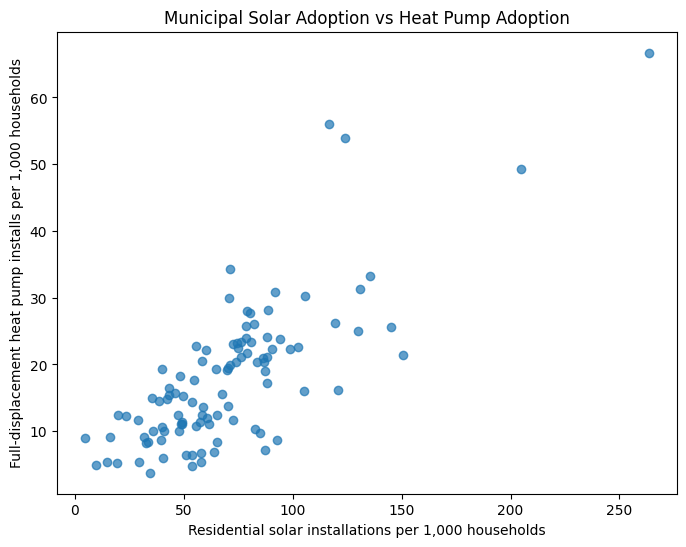

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    solar_hp["solar_per_1000_households"],
    solar_hp["installs_per_1000_full_disp_2024"],
    alpha=0.7
)

plt.xlabel("Residential solar installations per 1,000 households")
plt.ylabel("Full-displacement heat pump installs per 1,000 households")
plt.title("Municipal Solar Adoption vs Heat Pump Adoption")

plt.show()

In [27]:
import statsmodels.api as sm

model_data = solar_hp[[
    "installs_per_1000_full_disp_2024",
    "solar_per_1000_households",
    "gas_share_2013",
    "delivered_share_2013",
    "elec_per_hh_per_hdd_2023"
]].dropna()

X = model_data[[
    "solar_per_1000_households",
    "gas_share_2013",
    "delivered_share_2013",
    "elec_per_hh_per_hdd_2023"
]]

y = model_data["installs_per_1000_full_disp_2024"]

X = sm.add_constant(X)

solar_model = sm.OLS(y, X).fit()

print(solar_model.summary())

                                   OLS Regression Results                                   
Dep. Variable:     installs_per_1000_full_disp_2024   R-squared:                       0.747
Model:                                          OLS   Adj. R-squared:                  0.737
Method:                               Least Squares   F-statistic:                     70.97
Date:                              Wed, 24 Jun 2026   Prob (F-statistic):           7.81e-28
Time:                                      13:58:53   Log-Likelihood:                -314.36
No. Observations:                               101   AIC:                             638.7
Df Residuals:                                    96   BIC:                             651.8
Df Model:                                         4                                         
Covariance Type:                          nonrobust                                         
                                coef    std err          t      P>|t| 

In [ ]:
solar_hp.to_csv("heatpump_plus_pts_solar_municipality_dataset.csv", index=False)

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

os.listdir()

['.config',
 'pts_residential_solar_by_municipality.csv',
 'Solar-PV-Systems-in-MA-as-of-Jan-2025.xlsx',
 'final_dataset_clean.csv',
 'sample_data']

In [21]:
file_name = "Solar-PV-Systems-in-MA-as-of-Jan-2025.xlsx"

solar_raw = pd.read_excel(file_name, skiprows=9)

# Promote first row to header if needed
solar_raw.columns = solar_raw.iloc[0]
solar_raw = solar_raw.iloc[1:].copy()

# Clean column names
solar_raw.columns = (
    solar_raw.columns
    .astype(str)
    .str.replace("\n", " ", regex=False)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

solar_raw = solar_raw.reset_index(drop=True)

solar_raw.columns.tolist()

['Capacity (DC, kW)',
 'Date In Service',
 'Total Cost with Design Fees',
 'Total Grant',
 'City',
 'Zip',
 'County',
 'Program Name',
 'Facility Type',
 'Installer',
 'Module Manufacturer',
 'Inverter Manufacturer',
 'Meter Manufacturer',
 'Utility',
 '3rd Party Owner',
 'SREC Eligible',
 'Estimated Annual Production (kWhr)']